In [1]:
import os

DEVELOPMENT_MODE = False
# Detect if we're running in Google Colab
try:
    import google.colab

    IN_COLAB = True
    print("Running as a Colab notebook")
except:
    IN_COLAB = False

# Install if in Colab
if IN_COLAB:
    %pip install transformer_lens
    %pip install circuitsvis

# Hot reload in development mode & not running on the CD
if not IN_COLAB:
    from IPython import get_ipython

    ip = get_ipython()
    if 'autoreload' not in ip.extension_manager.loaded:
        ip.extension_manager.load_extension('autoreload')
        %autoreload 2

IN_GITHUB = os.getenv("GITHUB_ACTIONS") == "true"

In [2]:
# Plotly needs a different renderer for VSCode/Notebooks vs Colab argh
import plotly.io as pio

if IN_COLAB or not DEVELOPMENT_MODE:
    pio.renderers.default = "colab"
else:
    pio.renderers.default = "notebook_connected"
print(f"Using renderer: {pio.renderers.default}")

Using renderer: colab


In [3]:
import circuitsvis as cv

#testing if library works
cv.examples.hello("Dhirana")

In [4]:
# import stuff
import torch
import torch.nn as nn
import einops
from fancy_einsum import einsum
import tqdm.auto as tqdm
import plotly.express as px

from jaxtyping import Float
from functools import partial

/Users/dhirana/Codes/paper-replications/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
# import transformer_lens
import transformer_lens.utilities as utils
from transformer_lens.hook_points import (
    HookPoint,
) #hooking utilities

from transformer_lens import FactoredMatrix
from transformer_lens.model_bridge import TransformerBridge

W1028 23:43:19.420000 96528 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [6]:
torch.set_grad_enabled(False)

torch.autograd.grad_mode.set_grad_enabled(mode=False)

In [7]:
# Plotting helper functions:

def imshow(tensor, renderer=None, xaxis="", yaxis="", **kwargs):
    px.imshow(
        utils.to_numpy(tensor),
        color_continuous_midpoint=0.0,
        color_continuous_scale="RdBu",
        labels={"x": xaxis, "y": yaxis},
        **kwargs,
    ).show(renderer)


def line(tensor, renderer=None, xaxis="", yaxis="", **kwargs):
    px.line(y=utils.to_numpy(tensor), labels={"x": xaxis, "y": yaxis}, **kwargs).show(renderer)


def scatter(x, y, xaxis="", yaxis="", caxis="", renderer=None, **kwargs):
    x = utils.to_numpy(x)
    y = utils.to_numpy(y)
    px.scatter(y=y, x=x, labels={"x": xaxis, "y": yaxis, "color": caxis}, **kwargs).show(renderer)

In [8]:
device = utils.get_device()

In [9]:
# NBVAL_IGNORE_OUTPUT
model = TransformerBridge.boot_transformers("openai-community/gpt2", device=device)
model.enable_compatibility_mode(disable_warnings=True)  # for legacy HookedTransformer-equivalent numerics

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 15124.92it/s]


In [10]:
# now can try the model out by finding the loss on following text

model_description_text = """## Loading and Running Models

TransformerLens supports 9,000+ models across 50+ architecture families. You can load any of them in with `TransformerBridge.boot_transformers(MODEL_NAME)`. For this demo notebook we'll look at GPT-2 Small, an 80M parameter model, see the Available Models section for info on the rest.

To try the model out, let's find the loss on this text!"""
loss = model(model_description_text, return_type="loss")
print("Model loss:", loss)

# since loading openai-community/gpt2 model, aka working w an autoregressive LLM, the loss function is automatically Cross-Entropy Loss, specifically targetting next-token prediction.

# so a loss of tensor(4.5417) is v normal for the starting of a training/eval. Why tho? Ok cos gpt-2 has a vocab size of 50,257 possible tokens (words/word pieces), so if a model made competely random guesses across these 50k choices, its strrting loss is mathematically calculated as log(50257) = 10.82. But the model is not making random guesses, it has been pretrained on a large corpus of text, so its loss is obv much lower than 10.82, at 4.54. This means the model is doing a lot better than random guessing, but still has room for improvement. But ya 4.5417 means still got lot of room to improve :/

# btw see how its log(50257) even though usually probability is calculated as 1/50257 = 0.002%? 
# log happens cos of how we mathematically define "Loss". Loss isnt actl measured as raw probability but via Cross-Entropy Loss for which the formula is Loss = -ln(P) where P is the probability model gave to the correct word. so its actl Loss = -ln(1/50257) = ln(50257) = 10.82.

# we use log instead of just raw probability cos log is more numerically stable and easier to work with, especially when dealing with very small probabilities. So log is used for 2 reasons:

# 1. It scales small numbers: if a model predicts a correct word w v tiny probability, working w such tiny decimals can cause computer math errors (underfloww). So log turns these small probabilities into bigger numbers. 
# 2. Heavily penalises being confidently wrong: if a model predicts a wrong word w v high probability, log will give a v large loss value, which is good for training as it encourages the model to be more careful in its predictions.
# Cos if model is 100% sure (P=1), Loss = -ln(1) = 0 (Zero penalty)
# IF model is totally guessing (P=1/50257), Loss = -ln(1/50257) = ln(50257) = 10.82 (Moderate penalty)
# IF model is 99.99% confident int he wrong word, the prob for the correct word drops near 0, causing the log loss to skyrocket to 50+ or even 100+ (Severe penalty)


Model loss: tensor(4.5417)


Models can be run on a single string or a tensor of tokens (shape: [batch, position], all integers), and the possible return types are:

    "logits" (shape [batch, position, d_vocab], floats),
    "loss" (the cross-entropy loss when predicting the next token),
    "both" (a tuple of (logits, loss))
    None (run the model, but don't calculate the logits - this is faster when we only want to use intermediate activations)

# Caching all Activations

- tokens (input): the text you feed into the model is broken down into numbers that the AI understands
- logits (final answer): raw unnormalised prediction scores the model outputs at end. these logits are used to calculate the loss value of 4.5417 above, and to decide which word to guess next
- cache (hidden brain activity): massive dict containing a snapshot of every single internal calculation the model made along the way. Inside cache you'll find 1. what the model paid attention to (Attention heads), intermediate concepts it was processing (MLP activations), hidden states at layer 1,2,12 etc.

In [11]:
gpt2_text = "Natural language processing tasks, such as question answering, machine translation, reading comprehension, and summarization, are typically approached with supervised learning on taskspecific datasets."

gpt2_tokens = model.to_tokens(gpt2_text)
print(gpt2_tokens.device)

gpt2_logits, gpt2_cache = model.run_with_cache(gpt2_tokens, remove_batch_dim=True)

# the remove_batch_dim is set to True cos we only have 1 sentence aka single batch dimension. So the dimension's always gonna be length 1 anyways. If not when we use imshow later, Python will get confused cos it expects a 2D array but will get a 3D array wrapped in an extra empty layer.


cpu


In [12]:
# Now we can visualise the attention pattern of all the heads in layer 0. 

# GPT-2 has 12 different "Attention Heads" per layer. Aka 12 diff ppl looking at the same text from diff angles. 
# head_index: which of the 12 attention heads we're looking at
# destination_postition: the word that the model is currently tryna predict
# source_position: the past words the model's looking back to get context

In [13]:
print(type(gpt2_cache))
attention_pattern = gpt2_cache["pattern", 0, "attn"] # 0 cos we want layer 0 (very first layer of the model). attn tells it you want to see the attention scores. 

print(attention_pattern.shape)
gpt2_str_tokens = model.to_str_tokens(gpt2_tokens)

# model.to_str_tokens translates the numbers in the initial tensor back to the actl words they represent. So we can see which words the model is looking at when predicting the next word.

<class 'transformer_lens.ActivationCache.ActivationCache'>
torch.Size([12, 33, 33])


As you can see, it confirms that the class type is that gpt2_cache is a custom fictionary-like object built by the transformer_lens library.

The shape of our data: shows exact dimensions of the 3D block of numbers jsut pulled out. 
- 12 independent attention heads running in parallel on layer 0
- 33 tokens long text sampel fed into the model (aka rows of our grid) [destination positions]
- 33 past words the model's allowed to look back for context (columns of our grid) [source positions]

so its a 33 x 33 grid for each head. And every single square in the grid represents hjow much a specific word is focusing on another word. 

In [18]:
print("Layer 0 Head Attention patterns: ")

cv.attention.attention_heads(tokens=gpt2_str_tokens, attention=attention_pattern)

Layer 0 Head Attention patterns: 


So the above is a visual map of gpt-2's actual thought process on its ground floor (layer 0). 
tldr: darker cells carry more attenion. 

Key aspects:
- grid is lower triangular due to causal attention. A destination can only read previous words (positions), it can't look into the future.

Top Row:
- the 12 small boxes at the top represent the 12 independent "eyes" of layer 0. 

Bottom box:
- Y-axis: this is the word the mode's currently processing as it reads down the page
- X-axis: these are the past words the model's allowed to look back at to get context
- top right half is completely gray/blank cos of causal attention. When the model is processing the word "language" (row 2), its physically impossible for it to look ahead at the word "translaion" (column 12) for eg hence why this triangle shape


So what's going on here?
- the model is not trying to guess the word 'tasks' for eg. It has **already read** the word 'tasks' and is now trying to decide what word should come next. So when you look at row tasks (4), you're looking at the model's brain while its sitting on the word 'tasks'.
- the very first token <|endoftext|> acts like a resting spot. So if an attention head doesn't find a strong grammatical connection on teh current word, it dumps a chunk of its focus onto the first token. thats why teh first column tends to be lot darker. 
- see how the 3rd square is darker. When the model's sitting on the word 'tasks' (4), its actively looking back at the word 'language' (2). 

In this case, we only wanted the layer 0 attention patterns, but we are storing the internal activations from all locations in the model. It's convenient to have access to all activations, but this can be prohibitively expensive for memory use with larger models, batch sizes, or sequence lengths. In addition, we don't need to do the full forward pass through the model to collect layer 0 attention patterns. The following cell will collect only the layer 0 attention patterns and stop the forward pass at layer 1, requiring far less memory and compute.

In [15]:
attn_hook_name = "blocks.0.attn.hook_pattern"
attn_layer = 0
_, gpt2_attn_cache = model.run_with_cache(
    gpt2_tokens, remove_batch_dim=True, stop_at_layer=attn_layer + 1, names_filter=[attn_hook_name]
)
gpt2_attn = gpt2_attn_cache[attn_hook_name]
assert torch.allclose(gpt2_attn, attention_pattern)

# Hooks: Intervening on Activations

In [ ]:
# We know what operations go on inside - just not always what they mean.

# One key feature: hook points. Cos every activation inside the trnasformer is surrounded by a hook point, letting us edit it. We do this by adding a hook function to that activation. Note: PyTorch hooks act on layer which makes them a bit different from transformer_lens hooks. PyTorch hooks are more like "after the layer has done its thing, do this", whereas transformer_lens hooks are more like "before the layer does its thing, do this". So transformer_lens hooks are more flexible and powerful.

### Ablation

An ablation deletes one activation of the network, to see how performance on a task changes. Lotta change then that activation was impt (vice versa). Recall that activation is the resulting matrix of numbers (numerical tensor) calculated inside the model as input text passes through.

Now,
zero ablation (pruning): is a deletion by setting that part's output to zero. Sometimes used to mean deleting a weight rather than an activation.
    Questions:
        - What's the diff bw weight and activation? Weights are machinery settings (hardcoded permanent #s that stay the same no matter what text is typed into prompt. when downloading model files from HuggingFace, ur downloading weights). Activations are the actl temporary matrices of #s calculated on the fly when text passes thru the model. So if prompt changes, activations change instantly. 
        - also what does it mean to say this is This is arguably unprincipled, because the model may be using that part as a bias term (eg if that activation is always in the range [100, 102], then setting it to zero may break everything on all tasks)? Answer: a zero ablation is unprincipeld cos u kill an activation by manuallly forcing its numbers to 0. So model may crash not cause u deleted a critical feature, but cos u may have ruined a structural offset (bias term) that the rest of the network was relying on. 

mean ablation: set that part's output to its average. somewhat addresses bias term concern above but imperfectly cos it can throw the model off the manifold of "normal activations". Eg. if activations are always points on a circle, their mean becomes the origin which totally breaks things. 
    - so to fix the above bias problem, researchers invented mean ablation. meaning instead of setting the activation to 0, you run 1000 random sentences thru the model to find mean activation value and ovverwrite the activation with this mean. --> this way next layer still gets its expected baseline. 
    - this mean ablation fixes baseline issue above BUT, introduces a geometric probem. Cos 


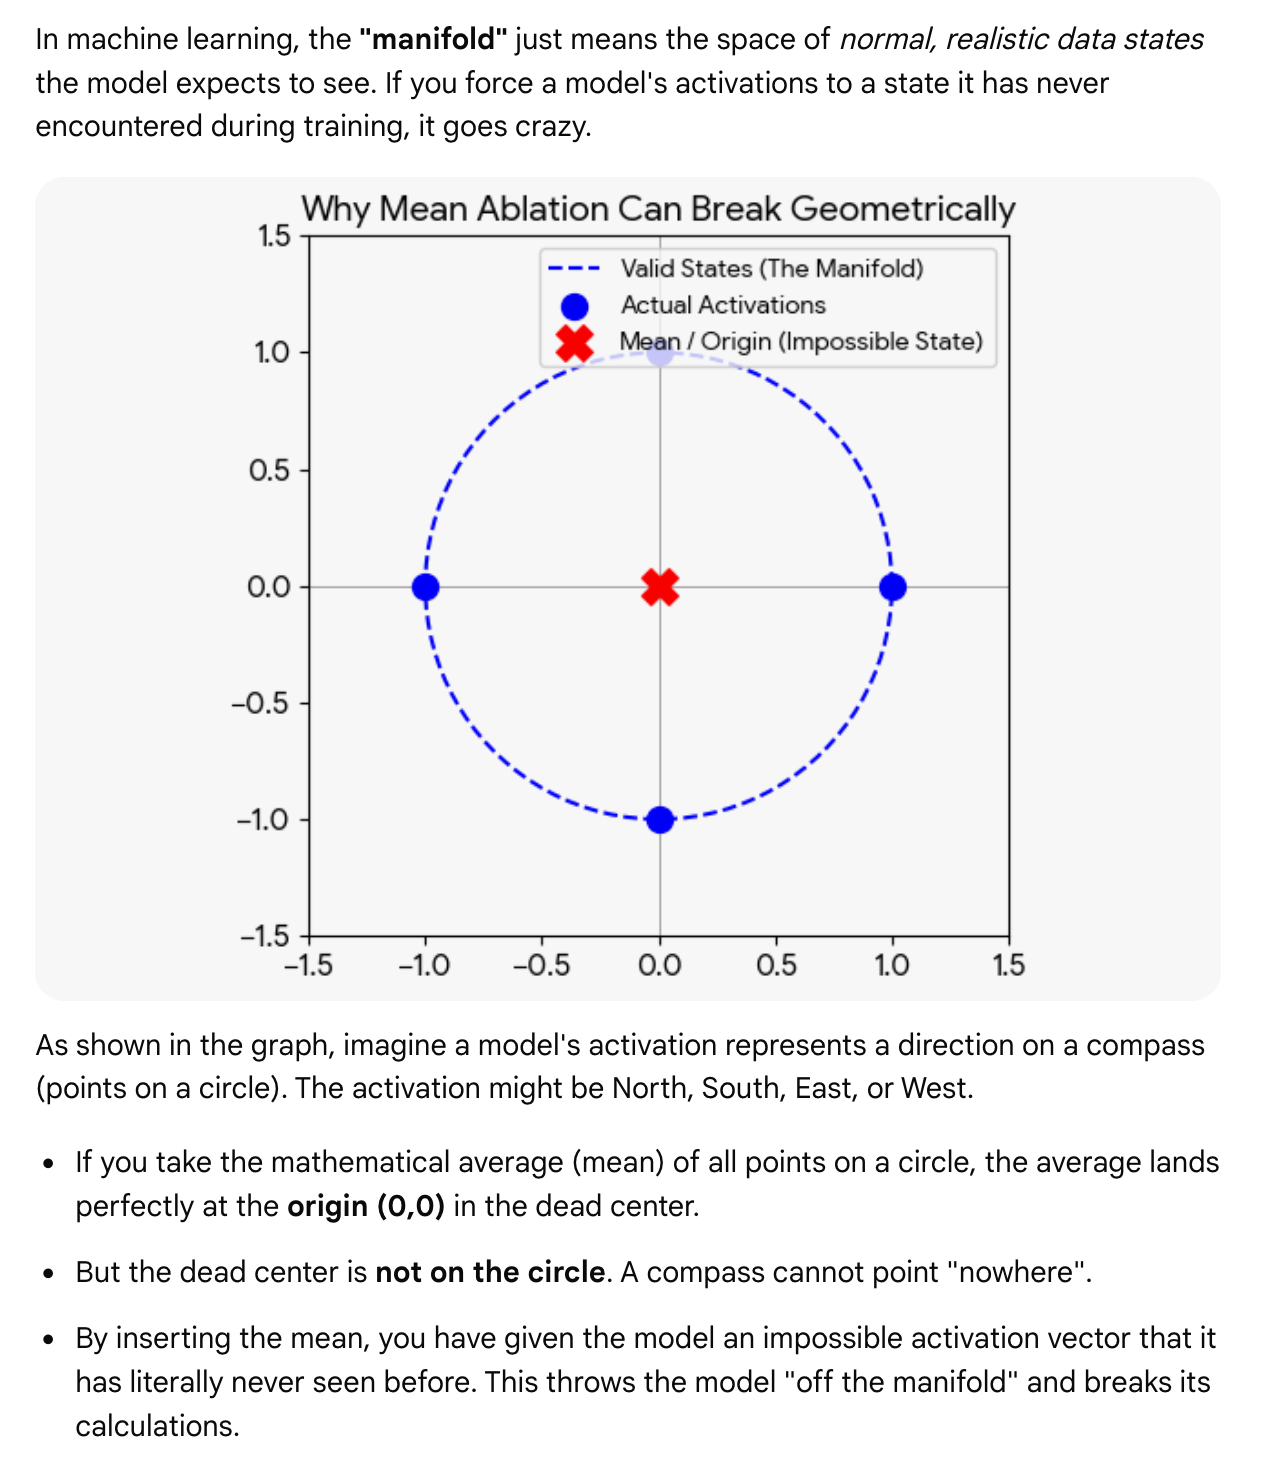


Random ablation (resampling): replaces the activation with the same activation on a randomly chosen other data point. 


Note: All these may be unreliable on models trained with dropout cos dropout automatically applies zero ablations to random activations at training time.

So now let's ablate head 8 in layer 0 of the text above. 

1. Create the head_ablation_hook function which takes 2 args (activation and hook). Edits in-place doesnt make a copy.

2. Get the right location within the transformer

3. Inject the hook run_with_hooks (temporary so when specific sentence finishes processing the hook disappears)

Essentially what we're saying is: Run the prompt but when u arrive at Layer 0's value activations, pause. Hand the data over to head_ablation_hook function so it can zero out the head. Put the modified data back on the conveyer belt and finish running. 

In [ ]:
layer_to_ablate = 0
head_index_to_ablate = 8

def head_ablation_hook(
        value: Float[torch.Tensor, "batch pos head_index d_head"],
        hook: HookPoint
        ) -> Float[torch.Tensor, "batch pos head_index d_head"]:
            print(f"Shape of the value tensor: {value.shape}")
            value[:, :, head_index_to_ablate, :] = 0.0 # this is the line that executed the ablation. cos its telling pytorch to keep the 1 batch, 33 token positions, got to head index 8 (9th head) and change all 64 of its internal numbers to 0.0. So this is like telling the model "pls ignore this head, don't use it to make your predictions".
            return value

original_loss = model(gpt2_tokens, return_type="loss")
ablated_loss = model.run_with_hooks(
        gpt2_tokens,
        return_type="loss",
        fwd_hooks=[(utils.get_act_name("v", layer_to_ablate), head_ablation_hook)],
)

print(f"Original Loss: {original_loss.item():.3f}")
print(f"Ablated Loss: {ablated_loss.item():.3f}")

Shape of the value tensor: torch.Size([1, 33, 12, 64])
Original Loss: 3.999
Ablated Loss: 5.453


Shape of value tensor: torch.Size([1, 33, 12, 64])
This is a 4D matrix representing the "Value vectors" right inside layer 0.
1 (bactch): ur evaluating exactly 1 sentence
33 (pos): ur text prompt is split into exactly 33 tokens by the tokenizer
12 (head_index): gpt2 small has 12 separate attention heads working in parallel on this layer
64 (d_head): each head gets a vector of 64 numbers to store the "meaning" or context it extracted for that token

Original loss: 3.99 model is healthy, relatively confident and accurate at predicting the next tokens in ur prompt. 
ABlated loss: overall performance got V worse. 

Conclusion: Layer 0, head 8 is doing heavy lifting for this text. 

# Activation Patching on the Indirect Object Identification Task

"After John and Mary went to the store, Mary gave a bottle of milk to..."

A well trained model knows the answer must be John. Why? Because Mary already gave the milk away so grammatically she has to give it to the other persion (indirect object). So to do this, mode must do 2 things:
1. Notice that "Mary" is repeated twice
2. Figure out who the other name is and output it "John"

https://dynalist.io/d/n2ZWtnoYHrU1s4vnFSAQ519J#z=iWsV3s5Kdd2ca3zNgXr5UPHa

https://colab.research.google.com/github/TransformerLensOrg/TransformerLens/blob/main/demos/Exploratory_Analysis_Demo.ipynb#scrollTo=gqCBFuRGMfwZ


In [ ]:
clean_prompt = "After John and Mary went to the store, Mary gave a bottle of milk to" #model shld predict john
corrupted_prompt = "After John and Mary went to the store, John gave a bottle of milk to" #model shld predict mary cos the sentence structure is swapped

clean_tokens = model.to_tokens(clean_prompt)
corrupted_tokens = model.to_tokens(corrupted_prompt)

# this function evaluates how confidently the model prefers the right answer over wrong answer
def logits_to_logit_diff(logits, correct_answer=" John", incorrect_answer=" Mary"):
    correct_index = model.to_single_token(correct_answer) #model.to_single_token maps a string value of a single token to the token index for that token
    # if the string is not a single token, it raises an error
    incorrect_index = model.to_single_token(incorrect_answer)
    return logits[0, -1, correct_index] - logits[0, -1, incorrect_index]
    # score for "john" - score for "mary"; -1 cos its the very last token position. so [0, -1, correct_index] accesses the score the model have to "John" at the very last token position


# We run on the clean prompt with the cache so we store activations to patch in later.
clean_logits, clean_cache = model.run_with_cache(clean_tokens)
clean_logit_diff = logits_to_logit_diff(clean_logits)
print(f"Clean logit difference: {clean_logit_diff.item():.3f}")

# We don't need to cache on the corrupted prompt.
corrupted_logits = model(corrupted_tokens)
corrupted_logit_diff = logits_to_logit_diff(corrupted_logits)
print(f"Corrupted logit difference: {corrupted_logit_diff.item():.3f}")

Clean logit difference: 4.276
Corrupted logit difference: -2.738


Key concept: Logit Difference

Clean logit difference: 4.276
- means when you run the healthy clean prompt, model assigns a much higher score to "john" than to "mary".
- Difference is a +4.276
- ie. model is massively confident that "john" is the correct next word.

Corrupted logit difference: -2.738
- When corrupted prompt is run, the score of mary becomes much higher than the score for john so value drops to a -2.738.
- proves the model has successfully changed its mind and is now heavily leaning towards "mary"

Ok so now imagine we're an electrician tryna fix a blacked-out neighbourhood.
What we did is: I went to a completley healthy neighbourhood and measured the normal voltage (4.276) then went to a broken neighbourhood and measured dead voltage (-2.738). 

Knowing these no.s doesnt fix blackout just tells us what perfect and broken looks like.

So no we need to go down the power lines pole by pole (layer) and hosue by house (position) to find the exact spot where the cable snapped. In a loop. So layer 0, word 1 working wire spliced in healthy neighbourhood - check if power is on now. If not, try layer 1, word 1. eep going. 

In [31]:
def residual_stream_patching_hook(
        resid_pre: Float[torch.Tensor, "batch_pos_d_model"],
        hook: HookPoint,
        position: int
) -> Float[torch.Tensor, "batch_pos_d_model"]:
    clean_resid_pre = clean_cache[hook.name]
    resid_pre[:, position, :] = clean_resid_pre[:, position, :]
    return resid_pre


# We make a tensor to store the results for each patching run. We put it on the model's device to avoid needing to move things between the GPU and CPU, which can be slow.
num_positions = len(clean_tokens[0])
ioi_patching_result = torch.zeros((model.cfg.n_layers, num_positions), device=model.cfg.device)

for layer in tqdm.tqdm(range(model.cfg.n_layers)):
    for position in range(num_positions):
        # Use functools.partial to create a temporary hook function with the position fixed
        temp_hook_fn = partial(residual_stream_patching_hook, position=position)
        # Run the model with the patching hook
        patched_logits = model.run_with_hooks(
            corrupted_tokens, fwd_hooks=[(utils.get_act_name("in", layer), temp_hook_fn)]
        )
        # Calculate the logit difference
        patched_logit_diff = logits_to_logit_diff(patched_logits).detach()
        # Store the result, normalizing by the clean and corrupted logit difference so it's between 0 and 1 (ish)
        ioi_patching_result[layer, position] = (patched_logit_diff - corrupted_logit_diff) / (
            clean_logit_diff - corrupted_logit_diff
        )

100%|██████████| 12/12 [00:06<00:00,  1.95it/s]


In [36]:
# Add the index to the end of the label, because plotly doesn't like duplicate labels
token_labels = [f"{token}_{index}" for index, token in enumerate(model.to_str_tokens(clean_tokens))]
imshow(
    ioi_patching_result,
    x=token_labels,
    xaxis="Position",
    yaxis="Layer",
    title="Normalized Logit Difference After Patching Residual Stream on the IOI Task",
)

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed